In [6]:
%pip -q install pandas numpy matplotlib seaborn nltk scikit-learn wordcloud

In [7]:
import os, re, html, warnings, collections, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.tokenize import RegexpTokenizer
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import stopwords, wordnet
from nltk.sentiment import SentimentIntensityAnalyzer

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from wordcloud import WordCloud

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Download the small NLTK resources needed by this notebook.
for resource in ["stopwords", "wordnet", "omw-1.4", "vader_lexicon", "punkt"]:
    try:
        nltk.download(resource, quiet=True)
    except Exception as e:
        print("Could not download", resource, ":", e)

print("Libraries imported successfully.")

Libraries imported successfully.


In [8]:
# Search the current folder and common Colab locations.
possible_paths = [
    "Tweets.csv"
]
DATA_PATH = next((p for p in possible_paths if os.path.exists(p)), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Tweets.csv was not found. Place it in the same folder as this notebook "
        "or upload it to /content in Google Colab."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumns:")
print(df.columns.tolist())
print("\\nMissing values:")
display(df.isna().sum().to_frame("missing values"))

Dataset shape: (14640, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


\nColumns:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']
\nMissing values:


,missing values
tweet_id,0
airline_sentiment,0
airline_sentiment_confidence,0
negativereason,5462
negativereason_confidence,4118
airline,0
airline_sentiment_gold,14600
name,0
negativereason_gold,14608
retweet_count,0


In [9]:
required_columns = ["text", "airline_sentiment", "airline"]
missing_required = [c for c in required_columns if c not in df.columns]
if missing_required:
    raise ValueError(f"Dataset is missing required columns: {missing_required}")

df["text"] = df["text"].fillna("").astype(str)
df["airline_sentiment"] = df["airline_sentiment"].astype(str).str.lower().str.strip()
df["airline"] = df["airline"].fillna("Unknown").astype(str)
df["tweet_created_dt"] = pd.to_datetime(df.get("tweet_created"), errors="coerce", utc=True)

print("Sentiment labels:")
display(df["airline_sentiment"].value_counts().to_frame("tweets"))
print("Airlines:", sorted(df["airline"].unique()))

Sentiment labels:


,tweets
airline_sentiment,
negative,9178
neutral,3099
positive,2363


Airlines: ['American', 'Delta', 'Southwest', 'US Airways', 'United', 'Virgin America']


In [10]:
sample_tweets = df.loc[df["text"].str.contains(r"@|#|https?://|[!?]{2,}", regex=True), "text"].head(8)
for tweet in sample_tweets:
    print("TWEET:", tweet)
    print("Naive split:", tweet.split())
    print("Regex tokens:", re.findall(r"@[A-Za-z0-9_]+|#[A-Za-z0-9_]+|https?://\\S+|[A-Za-z]+(?:'[A-Za-z]+)?|[^\\w\\s]", tweet))
    print("-" * 90)

TWEET: @VirginAmerica What @dhepburn said.
Naive split: ['@VirginAmerica', 'What', '@dhepburn', 'said.']
Regex tokens: ['@VirginAmerica', ' ', 'What', ' ', '@dhepburn', ' ', 'said', '.']
------------------------------------------------------------------------------------------
TWEET: @VirginAmerica plus you've added commercials to the experience... tacky.
Naive split: ['@VirginAmerica', 'plus', "you've", 'added', 'commercials', 'to', 'the', 'experience...', 'tacky.']
Regex tokens: ['@VirginAmerica', ' ', 'plus', ' ', "you've", ' ', 'added', ' ', 'commercials', ' ', 'to', ' ', 'the', ' ', 'experience', '.', '.', '.', ' ', 'tacky', '.']
------------------------------------------------------------------------------------------
TWEET: @VirginAmerica I didn't today... Must mean I need to take another trip!
Naive split: ['@VirginAmerica', 'I', "didn't", 'today...', 'Must', 'mean', 'I', 'need', 'to', 'take', 'another', 'trip!']
Regex tokens: ['@VirginAmerica', ' ', 'I', ' ', "didn't", ' ', 't

### Cleaning decisions

| Tweet feature | Treatment | Reason |
|---|---|---|
| `@handles` | Remove the handle | Usually identifies a user/brand, not the complaint itself. |
| URLs | Remove | URL strings add noise; the linked page is not present in this dataset. |
| Hashtags | Keep the word, remove `#` | `#badservice` still contains useful meaning. |
| Emojis | Convert common emojis to words where possible | Emojis can express sentiment; deleting all of them can lose meaning. |
| Stretched words | Reduce 3+ repeated letters to 2 | `sooooo` becomes `soo`, retaining emphasis without many spellings. |
| Contractions | Expand common negative contractions | `didn't` becomes `did not`, preserving negation. |
| Punctuation | Remove for word-frequency analysis | Punctuation is not generally a word feature, though `!` can express emphasis. |

These are practical choices, not universal rules. Always inspect examples before deciding.

In [11]:
emoji_map = {
    "😀": " happy ", "😃": " happy ", "😊": " happy ", "😍": " love ",
    "❤": " love ", "❤️": " love ", "👍": " good ", "👏": " good ",
    "😡": " angry ", "😠": " angry ", "😢": " sad ", "😭": " sad ",
    "😞": " sad ", "😩": " frustrated ", "🙁": " sad ", "😒": " annoyed "
}

def normalize_tweet(text):
    text = html.unescape(str(text)).lower()
    for emoji, meaning in emoji_map.items():
        text = text.replace(emoji, meaning)
    text = re.sub(r"https?://\\S+|www\\.\\S+", " ", text)  # remove URLs
    text = re.sub(r"@[a-z0-9_]+", " ", text)                  # remove handles
    text = re.sub(r"#([a-z0-9_]+)", r"\\1", text)            # keep hashtag word
    text = re.sub(r"([a-z])\\1{2,}", r"\\1\\1", text)     # reduce stretched letters
    # Expand common contractions, especially negative contractions.
    contractions = {
        "can't": "can not", "cannot": "can not", "won't": "will not",
        "don't": "do not", "doesn't": "does not", "didn't": "did not",
        "isn't": "is not", "aren't": "are not", "wasn't": "was not",
        "weren't": "were not", "haven't": "have not", "hasn't": "has not",
        "hadn't": "had not", "wouldn't": "would not", "couldn't": "could not",
        "shouldn't": "should not", "it's": "it is", "that's": "that is",
        "i'm": "i am", "you're": "you are", "we're": "we are",
        "they're": "they are", " i've": " i have"
    }
    for old, new in contractions.items():
        text = text.replace(old, new)
    text = re.sub(r"[^a-z0-9\\s']", " ", text)
    text = re.sub(r"\\s+", " ", text).strip()
    return text

df["normalized_text"] = df["text"].apply(normalize_tweet)
tokenizer = RegexpTokenizer(r"[a-z]+(?:'[a-z]+)?")
df["tokens_all"] = df["normalized_text"].apply(tokenizer.tokenize)

display(df[["text", "normalized_text", "tokens_all"]].head(10))

,text,normalized_text,tokens_all
0,@VirginAmerica What @dhepburn said.,what said,"[what, said]"
1,@VirginAmerica plus you've added commercials t...,plus you've added commercials to the experienc...,"[plus, you've, added, commercials, to, the, ex..."
2,@VirginAmerica I didn't today... Must mean I n...,i did not today must mean i need to take an...,"[i, did, not, today, must, mean, i, need, to, ..."
3,@VirginAmerica it's really aggressive to blast...,it is really aggressive to blast obnoxious en...,"[it, is, really, aggressive, to, blast, obnoxi..."
4,@VirginAmerica and it's a really big bad thing...,and it is a really big bad thing about it,"[and, it, is, a, really, big, bad, thing, abou..."
5,@VirginAmerica seriously would pay $30 a fligh...,seriously would pay 30 a flight for seats tha...,"[seriously, would, pay, a, flight, for, seats,..."
6,"@VirginAmerica yes, nearly every time I fly VX...",yes nearly every time i fly vx this ear worm...,"[yes, nearly, every, time, i, fly, vx, this, e..."
7,@VirginAmerica Really missed a prime opportuni...,really missed a prime opportunity for men with...,"[really, missed, a, prime, opportunity, for, m..."
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",well i did not but now i do d,"[well, i, did, not, but, now, i, do, d]"
9,"@VirginAmerica it was amazing, and arrived an ...",it was amazing and arrived an hour early you...,"[it, was, amazing, and, arrived, an, hour, ear..."


In [12]:
english_stops = set(stopwords.words("english"))
negation_words = {"no", "nor", "not", "never", "neither", "n't"}
custom_stopwords = english_stops - negation_words

def remove_stopwords(tokens, stop_set=custom_stopwords):
    return [w for w in tokens if w not in stop_set and len(w) > 1]

df["tokens_clean"] = df["tokens_all"].apply(remove_stopwords)
df["clean_text"] = df["tokens_clean"].apply(lambda x: " ".join(x))

examples = [
    "The flight was good",
    "The flight was not good",
    "I do not recommend this airline",
    "No one helped us"
]
for sentence in examples:
    toks = tokenizer.tokenize(normalize_tweet(sentence))
    print("\\nOriginal:", sentence)
    print("With standard stop words:", [w for w in toks if w not in english_stops])
    print("With custom stop words:", remove_stopwords(toks))

\nOriginal: The flight was good
With standard stop words: ['flight', 'good']
With custom stop words: ['flight', 'good']
\nOriginal: The flight was not good
With standard stop words: ['flight', 'good']
With custom stop words: ['flight', 'not', 'good']
\nOriginal: I do not recommend this airline
With standard stop words: ['recommend', 'airline']
With custom stop words: ['not', 'recommend', 'airline']
\nOriginal: No one helped us
With standard stop words: ['one', 'helped', 'us']
With custom stop words: ['no', 'one', 'helped', 'us']


In [13]:
vocab_sample = sorted(set(w for tokens in df["tokens_all"] for w in tokens))
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

comparison_words = ["delayed", "delays", "cancelled", "cancellation", "flying",
                    "flies", "better", "worst", "services", "amazing",
                    "running", "airlines", "friendly", "terrible"]
comparison = pd.DataFrame({
    "word": comparison_words,
    "stem": [stemmer.stem(w) for w in comparison_words],
    "lemma_noun": [lemmatizer.lemmatize(w) for w in comparison_words]
})
display(comparison)

stemmed_vocab = {stemmer.stem(w) for w in vocab_sample}
lemmatized_vocab = {lemmatizer.lemmatize(w) for w in vocab_sample}
print("Vocabulary before:", len(set(vocab_sample)))
print("Vocabulary after stemming:", len(stemmed_vocab))
print("Vocabulary after noun lemmatization:", len(lemmatized_vocab))

,word,stem,lemma_noun
0,delayed,delay,delayed
1,delays,delay,delay
2,cancelled,cancel,cancelled
3,cancellation,cancel,cancellation
4,flying,fli,flying
5,flies,fli,fly
6,better,better,better
7,worst,worst,worst
8,services,servic,service
9,amazing,amaz,amazing


Vocabulary before: 11686
Vocabulary after stemming: 9018
Vocabulary after noun lemmatization: 10768


In [14]:
def vocab_size(series):
    return len(set(itertools.chain.from_iterable(series)))

stages = {
    "Raw regex tokens": df["tokens_all"],
    "After stop-word removal": df["tokens_clean"]
}
stage_rows = []
for name, token_series in stages.items():
    lengths = token_series.apply(len)
    stage_rows.append({
        "stage": name,
        "vocabulary_size": vocab_size(token_series),
        "average_tokens_per_tweet": lengths.mean(),
        "empty_tweets": int((lengths == 0).sum()),
        "empty_tweets_percent": 100 * (lengths == 0).mean()
    })
cleaning_summary = pd.DataFrame(stage_rows)
display(cleaning_summary.round(2))

,stage,vocabulary_size,average_tokens_per_tweet,empty_tweets,empty_tweets_percent
0,Raw regex tokens,11686,16.53,0,0.00
1,After stop-word removal,11509,9.00,22,0.15


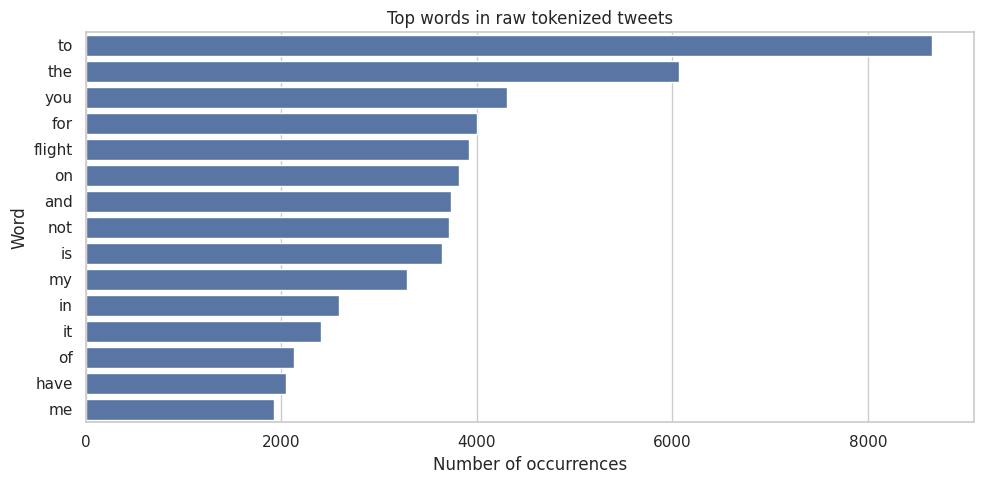

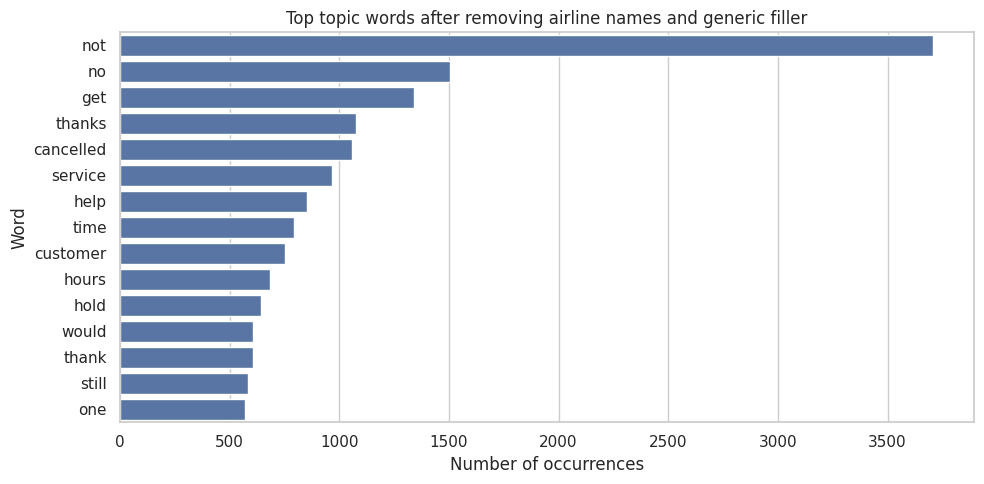

Most common raw terms: [('to', 8653), ('the', 6063), ('you', 4305), ('for', 4001), ('flight', 3923), ('on', 3815), ('and', 3733), ('not', 3709), ('is', 3644), ('my', 3289)]
Most common topic terms: [('not', 3709), ('no', 1507), ('get', 1342), ('thanks', 1078), ('cancelled', 1057), ('service', 965), ('help', 852), ('time', 793), ('customer', 754), ('hours', 683)]


In [15]:
all_airline_words = set()
for airline in df["airline"].dropna().unique():
    all_airline_words.update(tokenizer.tokenize(str(airline).lower()))
generic_words = {"airline", "airlines", "flight", "flights", "plane", "trip", "http", "co"}
excluded_for_topic_chart = custom_stopwords | all_airline_words | generic_words

def word_counts(token_lists, excluded=None):
    excluded = excluded or set()
    counter = collections.Counter()
    for tokens in token_lists:
        counter.update(w for w in tokens if w not in excluded and len(w) > 1)
    return counter

raw_counts = word_counts(df["tokens_all"])
topic_counts = word_counts(df["tokens_clean"], excluded_for_topic_chart)

def plot_top_words(counter, title, n=15):
    top = counter.most_common(n)
    if not top:
        print("No words available for", title)
        return
    words, counts = zip(*top)
    plt.figure(figsize=(10, 5))
    sns.barplot(x=list(counts), y=list(words))
    plt.title(title)
    plt.xlabel("Number of occurrences")
    plt.ylabel("Word")
    plt.tight_layout()
    plt.show()

plot_top_words(raw_counts, "Top words in raw tokenized tweets")
plot_top_words(topic_counts, "Top topic words after removing airline names and generic filler")
print("Most common raw terms:", raw_counts.most_common(10))
print("Most common topic terms:", topic_counts.most_common(10))

,word,positive_tfidf,negative_tfidf,difference_negative_minus_positive
1786,not,0.165494,0.539528,0.374034
1052,flight,0.327540,0.501478,0.173938
1773,no,0.054303,0.226254,0.171951
369,cancelled,0.031892,0.156808,0.124916
1303,hours,0.006034,0.112274,0.106240
1275,hold,0.006034,0.104766,0.098732
695,delayed,0.012929,0.085656,0.072726
1143,get,0.098262,0.168922,0.070660
1061,flightled,0.010343,0.076442,0.066098
358,call,0.013791,0.078830,0.065039


,word,positive_tfidf,negative_tfidf,difference_negative_minus_positive
2652,thanks,0.524064,0.053407,-0.470657
2649,thank,0.392186,0.013821,-0.378365
1182,great,0.203420,0.013821,-0.189599
1584,love,0.137912,0.011091,-0.126821
501,co,0.200834,0.077636,-0.123198
1170,good,0.143083,0.026447,-0.116636
1310,http,0.187043,0.074565,-0.112478
199,awesome,0.084471,0.003071,-0.081400
243,best,0.089643,0.010750,-0.078893
1737,much,0.093952,0.016210,-0.077743


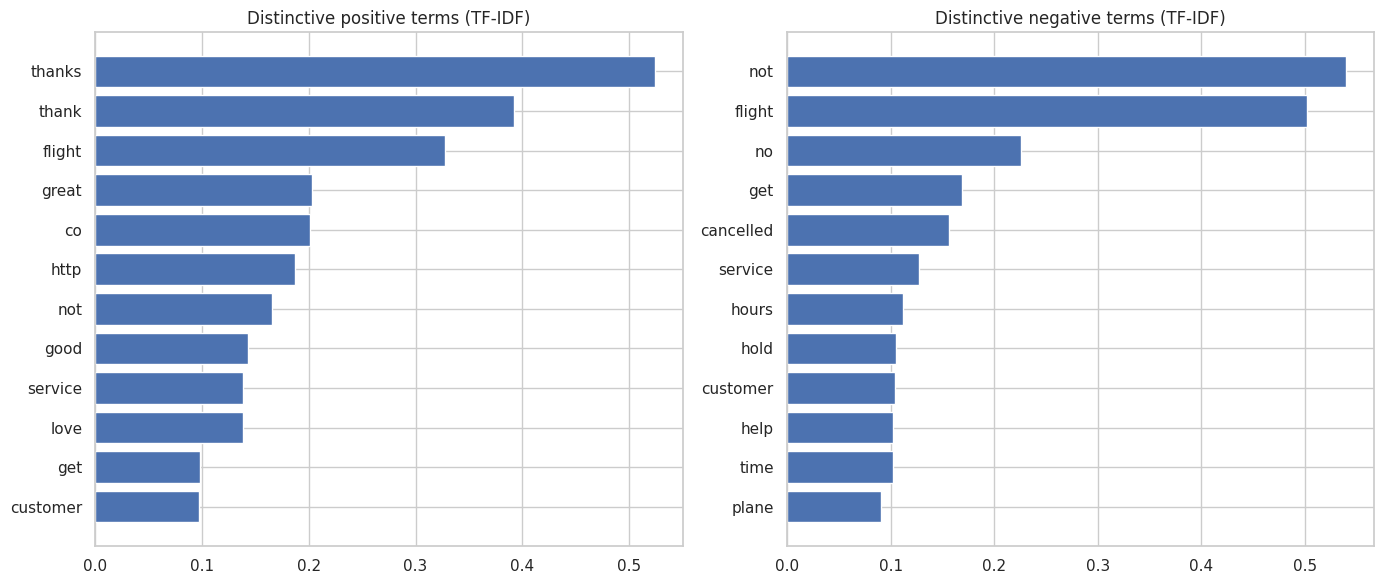

In [16]:
positive_docs = df.loc[df["airline_sentiment"] == "positive", "clean_text"]
negative_docs = df.loc[df["airline_sentiment"] == "negative", "clean_text"]
group_docs = [" ".join(positive_docs), " ".join(negative_docs)]

tfidf = TfidfVectorizer(stop_words=list(custom_stopwords), ngram_range=(1, 1), max_features=3000)
X_group = tfidf.fit_transform(group_docs)
terms = np.array(tfidf.get_feature_names_out())
tfidf_df = pd.DataFrame({
    "word": terms,
    "positive_tfidf": X_group.toarray()[0],
    "negative_tfidf": X_group.toarray()[1]
})
tfidf_df["difference_negative_minus_positive"] = tfidf_df["negative_tfidf"] - tfidf_df["positive_tfidf"]
display(tfidf_df.sort_values("difference_negative_minus_positive", ascending=False).head(15))
display(tfidf_df.sort_values("difference_negative_minus_positive").head(15))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
pos_top = tfidf_df.nlargest(12, "positive_tfidf").sort_values("positive_tfidf")
neg_top = tfidf_df.nlargest(12, "negative_tfidf").sort_values("negative_tfidf")
axes[0].barh(pos_top["word"], pos_top["positive_tfidf"])
axes[0].set_title("Distinctive positive terms (TF-IDF)")
axes[1].barh(neg_top["word"], neg_top["negative_tfidf"])
axes[1].set_title("Distinctive negative terms (TF-IDF)")
plt.tight_layout()
plt.show()

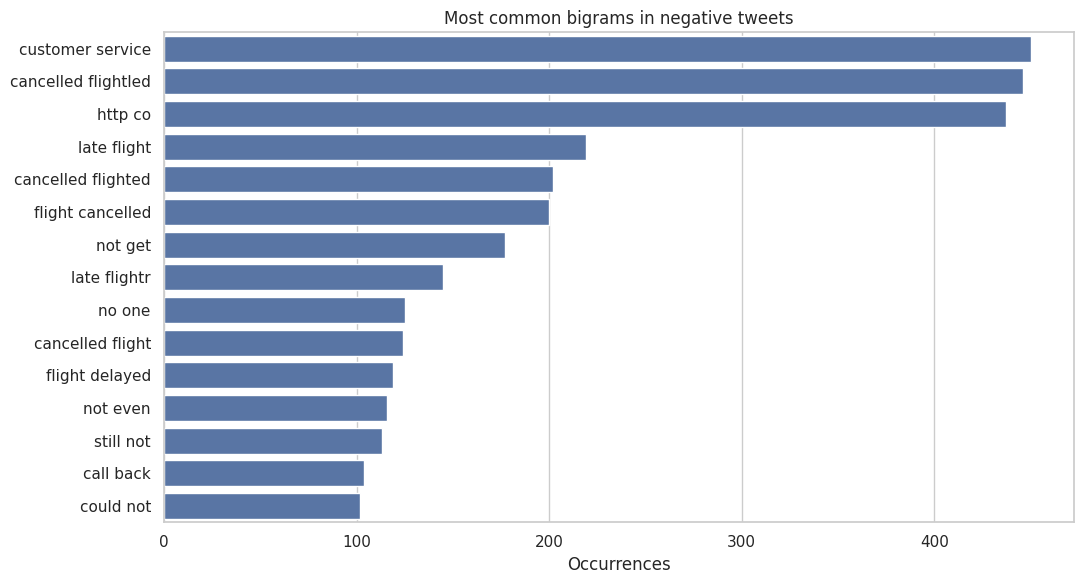

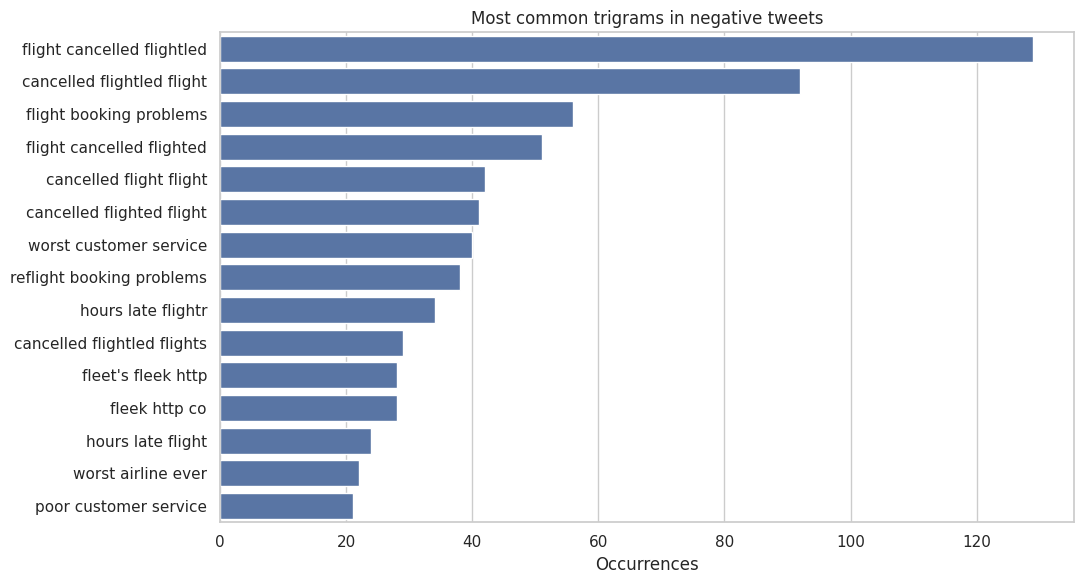

Top negative bigrams: [('customer service', 450), ('cancelled flightled', 446), ('http co', 437), ('late flight', 219), ('cancelled flighted', 202), ('flight cancelled', 200), ('not get', 177), ('late flightr', 145), ('no one', 125), ('cancelled flight', 124), ('flight delayed', 119), ('not even', 116), ('still not', 113), ('call back', 104), ('could not', 102), ('booking problems', 97), ('flightled flight', 92), ('flight not', 89), ('hold hours', 68), ('still no', 65)]


In [17]:
def ngram_counts(token_lists, n=2, excluded=None):
    excluded = excluded or set()
    c = collections.Counter()
    for tokens in token_lists:
        filtered = [w for w in tokens if w not in excluded]
        c.update(zip(*(filtered[i:] for i in range(n))))
    return c

negative_tokens = df.loc[df["airline_sentiment"] == "negative", "tokens_clean"]
bigram_counts = ngram_counts(negative_tokens, 2)
trigram_counts = ngram_counts(negative_tokens, 3)

def plot_ngrams(counter, title, n=15):
    top = counter.most_common(n)
    if not top:
        print("No phrases found.")
        return
    labels = [" ".join(k) for k, v in top]
    values = [v for k, v in top]
    plt.figure(figsize=(11, 6))
    sns.barplot(x=values, y=labels)
    plt.title(title)
    plt.xlabel("Occurrences")
    plt.tight_layout()
    plt.show()

plot_ngrams(bigram_counts, "Most common bigrams in negative tweets")
plot_ngrams(trigram_counts, "Most common trigrams in negative tweets")
print("Top negative bigrams:", [(" ".join(k), v) for k, v in bigram_counts.most_common(20)])

In [32]:
# Search phrase patterns that may indicate operational problems.
operational_patterns = [
    "customer service", "call center", "hold time", "lost bag", "checked bag",
    "missed connection", "cancelled flight", "cancelled my", "delayed flight",
    "late flight", "flight delay", "no response", "never again", "not helpful",
    "not good", "not happy"
]
negative_text_lower = df.loc[df["airline_sentiment"] == "negative", "normalized_text"]
phrase_evidence = []
for phrase in operational_patterns:
    count = negative_text_lower.str.contains(r"\\b" + re.escape(phrase) + r"\\b", regex=True).sum()
    if count:
        phrase_evidence.append((phrase, int(count)))
display(pd.DataFrame(phrase_evidence, columns=["phrase", "negative_tweet_count"]).sort_values(
    "negative_tweet_count", ascending=False
))

,phrase,negative_tweet_count


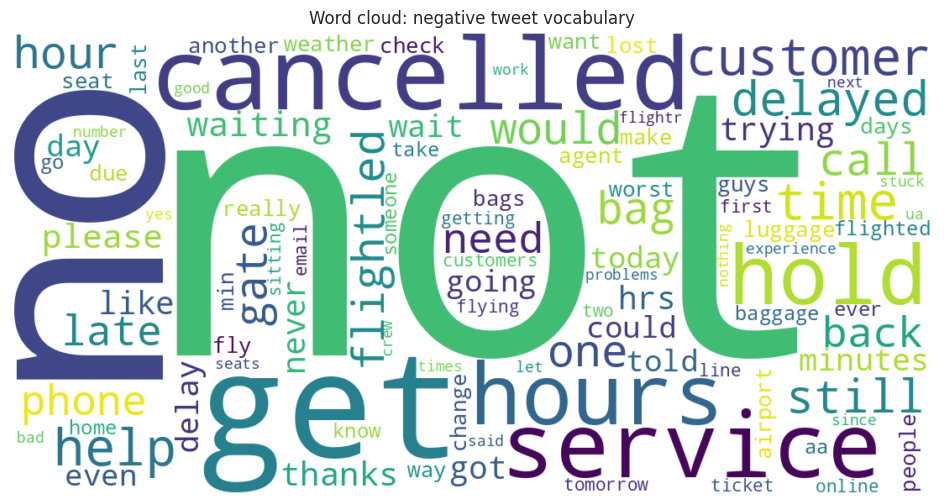

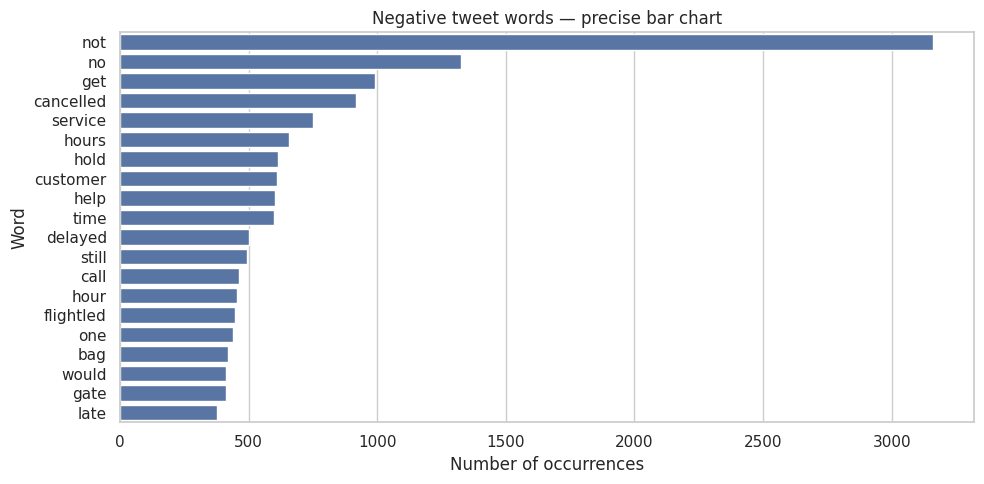

In [19]:
negative_words = word_counts(negative_tokens, excluded_for_topic_chart)
if negative_words:
    wc = WordCloud(width=1100, height=550, background_color="white",
                   collocations=False, max_words=100).generate_from_frequencies(negative_words)
    plt.figure(figsize=(13, 6))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word cloud: negative tweet vocabulary")
    plt.show()
plot_top_words(negative_words, "Negative tweet words — precise bar chart", 20)

In [20]:
try:
    sia = SentimentIntensityAnalyzer()
except LookupError:
    nltk.download("vader_lexicon")
    sia = SentimentIntensityAnalyzer()

def vader_class(text):
    compound = sia.polarity_scores(str(text))["compound"]
    if compound >= 0.05:
        label = "positive"
    elif compound <= -0.05:
        label = "negative"
    else:
        label = "neutral"
    return pd.Series([compound, label])

df[["vader_compound", "vader_sentiment"]] = df["text"].apply(vader_class)
valid = df[df["airline_sentiment"].isin(["positive", "neutral", "negative"])].copy()
labels = ["negative", "neutral", "positive"]
print("Overall accuracy:", round(accuracy_score(valid["airline_sentiment"], valid["vader_sentiment"]), 3))
print("Macro F1:", round(f1_score(valid["airline_sentiment"], valid["vader_sentiment"], average="macro"), 3))
print("\\nClassification report:")
print(classification_report(valid["airline_sentiment"], valid["vader_sentiment"], labels=labels, zero_division=0))

Overall accuracy: 0.543
Macro F1: 0.51
\nClassification report:
              precision    recall  f1-score   support

    negative       0.90      0.50      0.64      9178
     neutral       0.38      0.43      0.41      3099
    positive       0.34      0.87      0.49      2363

    accuracy                           0.54     14640
   macro avg       0.54      0.60      0.51     14640
weighted avg       0.70      0.54      0.57     14640



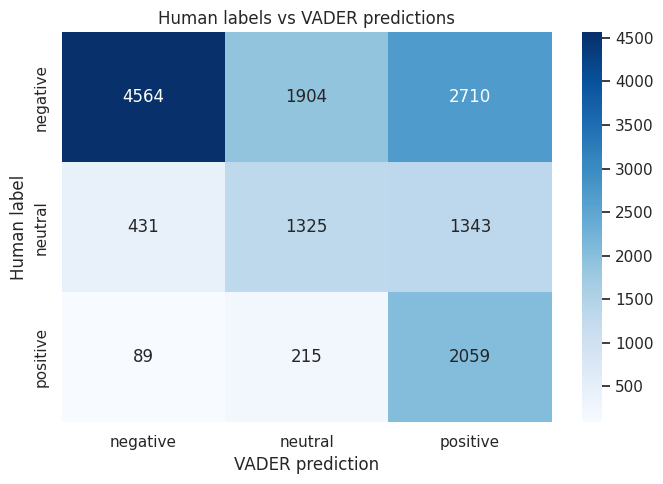

,precision,recall,f1-score,support
negative,0.897718,0.497276,0.640022,9178.0
neutral,0.384727,0.427557,0.405013,3099.0
positive,0.336878,0.871350,0.485900,2363.0


The weakest class by F1 is: neutral


In [21]:
cm = confusion_matrix(valid["airline_sentiment"], valid["vader_sentiment"], labels=labels)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("VADER prediction")
plt.ylabel("Human label")
plt.title("Human labels vs VADER predictions")
plt.tight_layout()
plt.show()

per_class = pd.DataFrame(classification_report(
    valid["airline_sentiment"], valid["vader_sentiment"],
    labels=labels, output_dict=True, zero_division=0
)).T.loc[labels, ["precision", "recall", "f1-score", "support"]]
display(per_class)
print("The weakest class by F1 is:", per_class["f1-score"].idxmin())

In [22]:
disagreements = valid[valid["airline_sentiment"] != valid["vader_sentiment"]].copy()

def disagreement_cause(text):
    t = str(text).lower()
    if re.search(r"\\b(not|no|never|neither|hardly)\\b", t):
        return "Negation"
    if any(x in t for x in ["yeah right", "great job", "thanks for nothing", "just wonderful", "love being"]):
        return "Possible sarcasm"
    if any(x in t for x in ["but", "although", "however", "on the other hand"]):
        return "Mixed feelings"
    if any(x in t for x in ["delay", "delayed", "cancel", "cancelled", "canceled",
                            "baggage", "luggage", "missed connection", "stranded"]):
        return "Operational vocabulary"
    return "Other / unclear"

disagreements["disagreement_cause"] = disagreements["text"].apply(disagreement_cause)
display(disagreements["disagreement_cause"].value_counts().to_frame("mismatch_count"))
display(disagreements[["text", "airline_sentiment", "vader_sentiment",
                       "vader_compound", "disagreement_cause"]].head(20))

,mismatch_count
disagreement_cause,
Other / unclear,5252
Operational vocabulary,739
Mixed feelings,675
Possible sarcasm,26


,text,airline_sentiment,vader_sentiment,vader_compound,disagreement_cause
1,@VirginAmerica plus you've added commercials t...,positive,neutral,0.0000,Other / unclear
7,@VirginAmerica Really missed a prime opportuni...,neutral,positive,0.1458,Other / unclear
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",positive,negative,-0.3477,Mixed feelings
10,@VirginAmerica did you know that suicide is th...,neutral,negative,-0.8555,Other / unclear
13,@VirginAmerica @virginmedia I'm flying your #f...,positive,neutral,0.0000,Other / unclear
16,@VirginAmerica So excited for my first cross c...,positive,negative,-0.5566,Mixed feelings
17,@VirginAmerica I flew from NYC to SFO last we...,negative,positive,0.5754,Other / unclear
18,I ❤️ flying @VirginAmerica. ☺️👍,positive,neutral,0.0000,Other / unclear
20,@VirginAmerica why are your first fares in May...,negative,neutral,0.0000,Other / unclear
23,@VirginAmerica will you be making BOS&gt;LAS n...,neutral,negative,-0.2960,Other / unclear


In [23]:
test_tweets = [
    "Great, my flight was cancelled again. Wonderful service!",
    "I am not happy with the delay, but the crew was kind.",
    "The food was good, but I missed my connection and lost my bag."
]
for t in test_tweets:
    print("\\nTweet:", t)
    print("VADER scores:", sia.polarity_scores(t))
    print("VADER class:", vader_class(t).iloc[1])
print("\\nInterpretation:")
print("1) Sarcasm: positive words like great/wonderful conflict with the cancelled flight.")
print("2) Negation and mixed sentiment: not happy is negative, while kind is positive.")
print("3) Mixed operational outcomes: good food does not cancel the missed connection and lost bag.")

\nTweet: Great, my flight was cancelled again. Wonderful service!
VADER scores: {'neg': 0.133, 'neu': 0.331, 'pos': 0.536, 'compound': 0.7959}
VADER class: positive
\nTweet: I am not happy with the delay, but the crew was kind.
VADER scores: {'neg': 0.225, 'neu': 0.492, 'pos': 0.283, 'compound': 0.4499}
VADER class: positive
\nTweet: The food was good, but I missed my connection and lost my bag.
VADER scores: {'neg': 0.344, 'neu': 0.539, 'pos': 0.117, 'compound': -0.5859}
VADER class: negative
\nInterpretation:
1) Sarcasm: positive words like great/wonderful conflict with the cancelled flight.
2) Negation and mixed sentiment: not happy is negative, while kind is positive.
3) Mixed operational outcomes: good food does not cancel the missed connection and lost bag.


In [24]:
if "airline_sentiment_confidence" in df.columns:
    confidence_df = valid.dropna(subset=["airline_sentiment_confidence"]).copy()
    high_conf = confidence_df[confidence_df["airline_sentiment_confidence"] >= 0.80]
    rows = []
    for name, subset in [("All available labels", confidence_df), ("Confidence >= 0.80", high_conf)]:
        rows.append({
            "subset": name,
            "tweets": len(subset),
            "accuracy": accuracy_score(subset["airline_sentiment"], subset["vader_sentiment"]) if len(subset) else np.nan,
            "macro_f1": f1_score(subset["airline_sentiment"], subset["vader_sentiment"], average="macro") if len(subset) else np.nan
        })
    display(pd.DataFrame(rows).round(3))
else:
    print("No airline_sentiment_confidence column is available.")

,subset,tweets,accuracy,macro_f1
0,All available labels,14640,0.543,0.510
1,Confidence >= 0.80,10459,0.586,0.529


negativereason,Bad Flight,Can't Tell,Cancelled Flight,Customer Service Issue,Damaged Luggage,Flight Attendant Complaints,Flight Booking Problems,Late Flight,Lost Luggage,longlines
airline,,,,,,,,,,
American,4.4,10.1,12.6,39.2,0.6,4.4,6.6,12.7,7.6,1.7
Delta,6.7,19.5,5.3,20.8,1.2,6.3,4.6,28.2,6.0,1.5
Southwest,7.6,13.4,13.7,33.0,1.2,3.2,5.1,12.8,7.6,2.4
US Airways,4.6,10.9,8.4,35.8,0.5,5.4,5.4,20.0,6.8,2.2
United,8.2,14.4,6.9,25.9,0.8,6.4,5.5,19.9,10.2,1.8
Virgin America,10.5,12.2,9.9,33.1,2.2,2.8,15.5,9.4,2.8,1.7


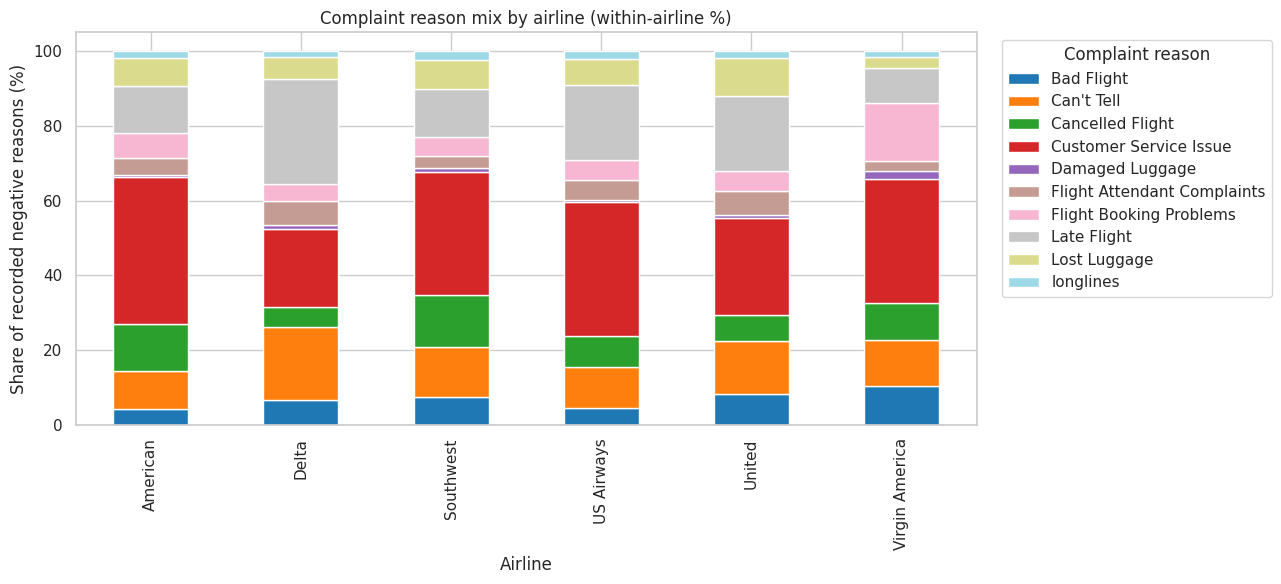

In [25]:
if "negativereason" in df.columns:
    neg_reason_df = df[df["airline_sentiment"] == "negative"].dropna(subset=["negativereason"]).copy()
    reason_counts = pd.crosstab(neg_reason_df["airline"], neg_reason_df["negativereason"])
    reason_share = reason_counts.div(reason_counts.sum(axis=1), axis=0) * 100
    display(reason_share.round(1))
    ax = reason_share.plot(kind="bar", stacked=True, figsize=(13, 6), colormap="tab20")
    ax.set_title("Complaint reason mix by airline (within-airline %)")
    ax.set_ylabel("Share of recorded negative reasons (%)")
    ax.set_xlabel("Airline")
    ax.legend(title="Complaint reason", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    print("No negativereason column found.")

,total_tweets,negative_tweets,positive_tweets,neutral_tweets,negative_share_pct
airline,,,,,
US Airways,2913,2263,269,381,77.7
American,2759,1960,336,463,71.0
United,3822,2633,492,697,68.9
Southwest,2420,1186,570,664,49.0
Delta,2222,955,544,723,43.0
Virgin America,504,181,152,171,35.9


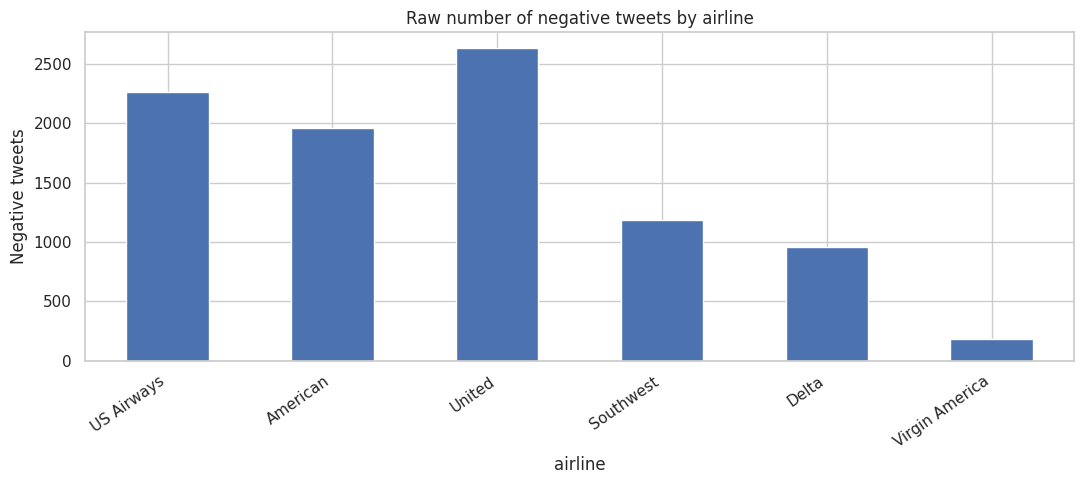

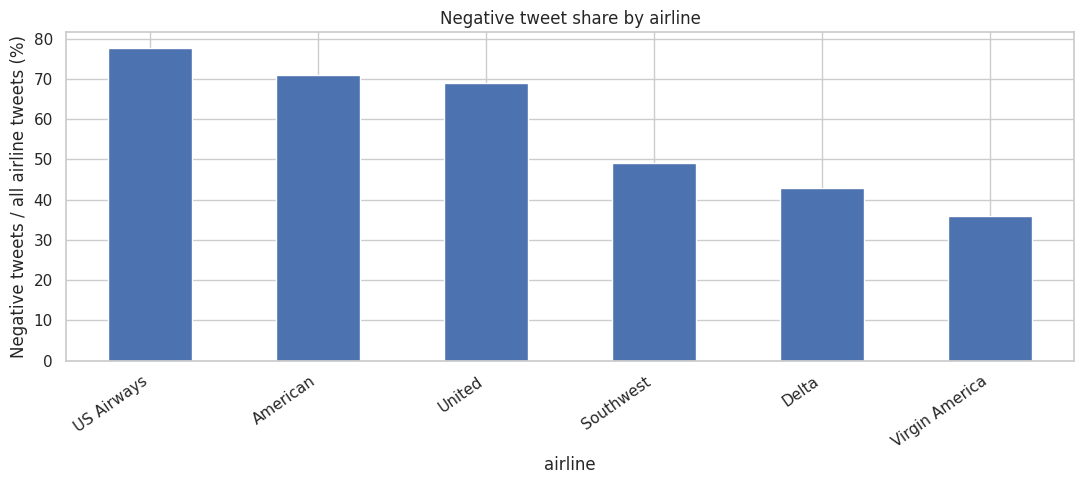

In [26]:
airline_summary = df.groupby("airline").agg(
    total_tweets=("text", "size"),
    negative_tweets=("airline_sentiment", lambda x: (x == "negative").sum()),
    positive_tweets=("airline_sentiment", lambda x: (x == "positive").sum()),
    neutral_tweets=("airline_sentiment", lambda x: (x == "neutral").sum())
)
airline_summary["negative_share_pct"] = 100 * airline_summary["negative_tweets"] / airline_summary["total_tweets"]
airline_summary = airline_summary.sort_values("negative_share_pct", ascending=False)
display(airline_summary.round(1))

fig, ax = plt.subplots(figsize=(11, 5))
airline_summary["negative_tweets"].plot(kind="bar", ax=ax)
ax.set_title("Raw number of negative tweets by airline")
ax.set_ylabel("Negative tweets")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
airline_summary["negative_share_pct"].plot(kind="bar", ax=ax)
ax.set_title("Negative tweet share by airline")
ax.set_ylabel("Negative tweets / all airline tweets (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

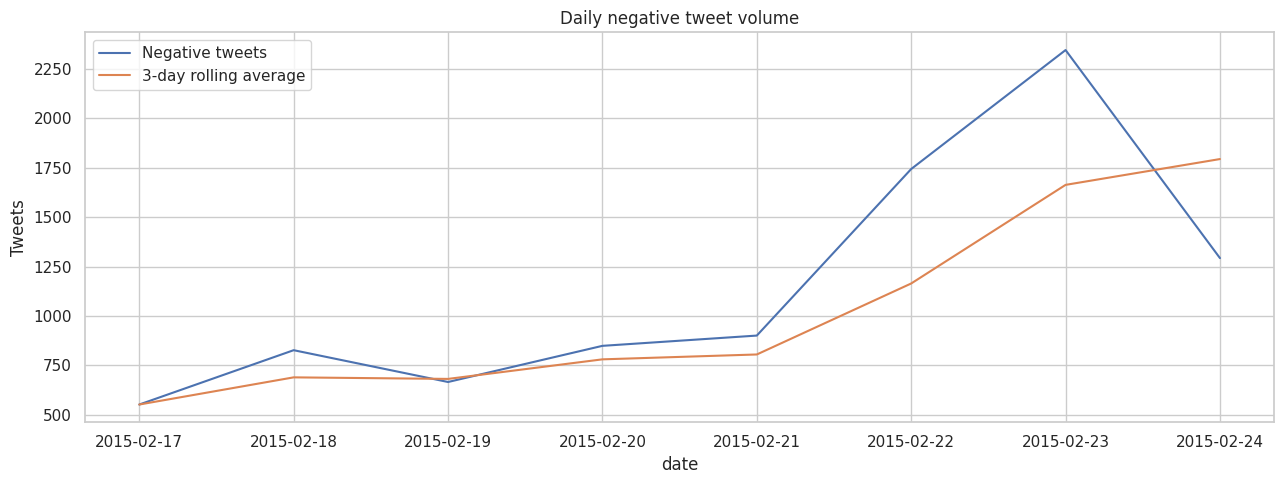

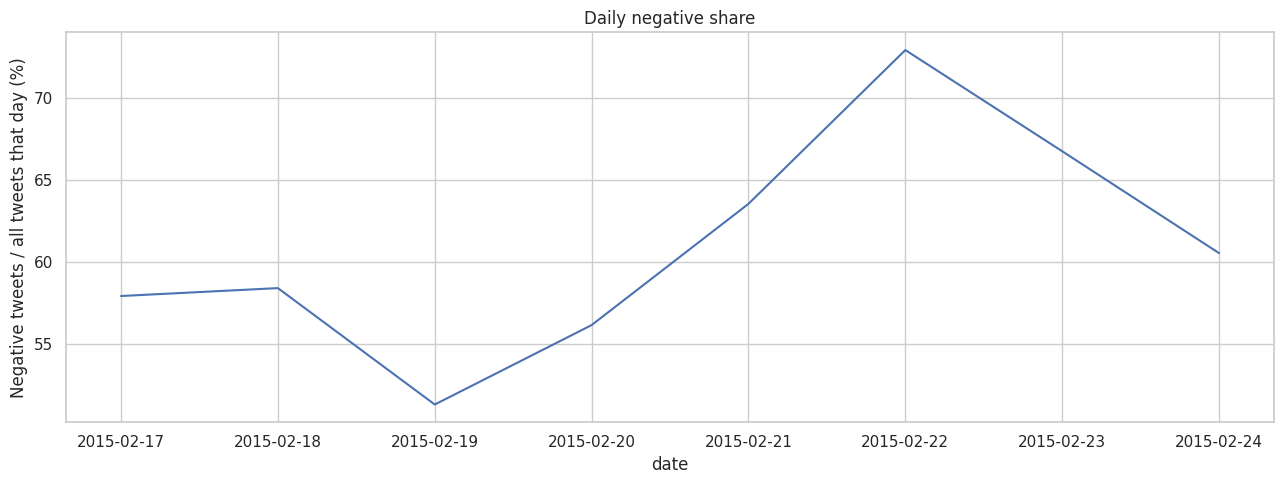

,total,negative,negative_share_pct
date,,,
2015-02-22,2392,1744,72.909699
2015-02-23,3515,2346,66.742532
2015-02-21,1418,901,63.540197
2015-02-24,2136,1293,60.533708
2015-02-18,1416,827,58.403955
2015-02-17,953,552,57.922350
2015-02-20,1512,849,56.150794
2015-02-19,1298,666,51.309707


In [27]:
time_df = df.dropna(subset=["tweet_created_dt"]).copy()
time_df["date"] = time_df["tweet_created_dt"].dt.date
daily = time_df.groupby("date").agg(
    total=("text", "size"),
    negative=("airline_sentiment", lambda x: (x == "negative").sum())
)
daily["negative_share_pct"] = 100 * daily["negative"] / daily["total"]
fig, ax = plt.subplots(figsize=(13, 5))
daily["negative"].plot(ax=ax, label="Negative tweets")
daily["negative"].rolling(3, min_periods=1).mean().plot(ax=ax, label="3-day rolling average")
ax.set_title("Daily negative tweet volume")
ax.set_ylabel("Tweets")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 5))
daily["negative_share_pct"].plot(ax=ax)
ax.set_title("Daily negative share")
ax.set_ylabel("Negative tweets / all tweets that day (%)")
plt.tight_layout()
plt.show()
display(daily.sort_values("negative_share_pct", ascending=False).head(10))

In [28]:
priority_df = df[df["airline_sentiment"] == "negative"].copy()
priority_df["retweet_count"] = pd.to_numeric(priority_df.get("retweet_count", 0), errors="coerce").fillna(0)
priority_df["has_reason"] = priority_df.get("negativereason", pd.Series(index=priority_df.index)).notna().astype(int)
priority_df["priority_score"] = (
    2 * priority_df["has_reason"] +
    np.log1p(priority_df["retweet_count"])
)
priority_df = priority_df.sort_values("priority_score", ascending=False)
display(priority_df[["airline", "negativereason", "retweet_count", "priority_score", "text"]].head(15))

,airline,negativereason,retweet_count,priority_score,text
11596,US Airways,Late Flight,44,5.806662,@USAirways 5 hr flight delay and a delay when ...
11582,US Airways,Can't Tell,32,5.496508,@USAirways of course never again tho . Thanks ...
7132,Delta,Can't Tell,31,5.465736,STOP. USING.THIS.WORD. IF. YOU'RE. A. COMPANY....
7115,Delta,Can't Tell,22,5.135494,can you not? RT @JetBlue Our fleet's on fleek....
7027,Delta,Can't Tell,18,4.944439,"Just in case you needed confirmation that ""on ..."
4144,United,Flight Booking Problems,7,4.079442,@united But I got a bad exchange rate so want ...
7134,Delta,Can't Tell,7,4.079442,“@JetBlue: Our fleet's on fleek. http://t.co/L...
4127,United,Flight Booking Problems,5,3.791759,@united @UnitedAppeals @gg8929 What kind of hy...
12680,American,Cancelled Flight,5,3.791759,@AmericanAir Cancelled Flight my flight saying...
4122,United,Flight Booking Problems,4,3.609438,@united @gg8929 so why did you Cancelled Fligh...


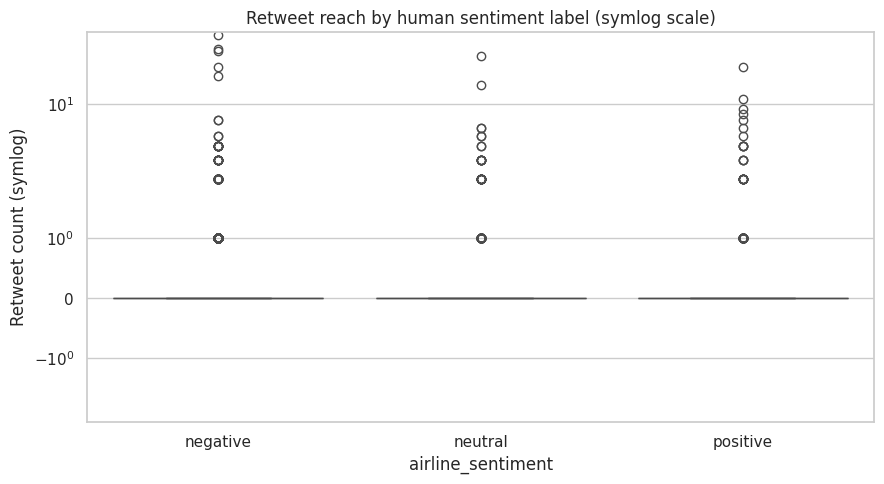

,count,mean,std,min,25%,50%,75%,max
airline_sentiment,,,,,,,,
negative,9178.0,0.09,0.79,0.0,0.0,0.0,0.0,44.0
neutral,3099.0,0.06,0.66,0.0,0.0,0.0,0.0,28.0
positive,2363.0,0.07,0.66,0.0,0.0,0.0,0.0,22.0


In [29]:
if "retweet_count" in df.columns:
    reach_df = df.copy()
    reach_df["retweet_count"] = pd.to_numeric(reach_df["retweet_count"], errors="coerce").fillna(0)
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=reach_df, x="airline_sentiment", y="retweet_count",
                order=["negative", "neutral", "positive"])
    plt.yscale("symlog")
    plt.title("Retweet reach by human sentiment label (symlog scale)")
    plt.ylabel("Retweet count (symlog)")
    plt.tight_layout()
    plt.show()
    display(reach_df.groupby("airline_sentiment")["retweet_count"].describe().round(2))

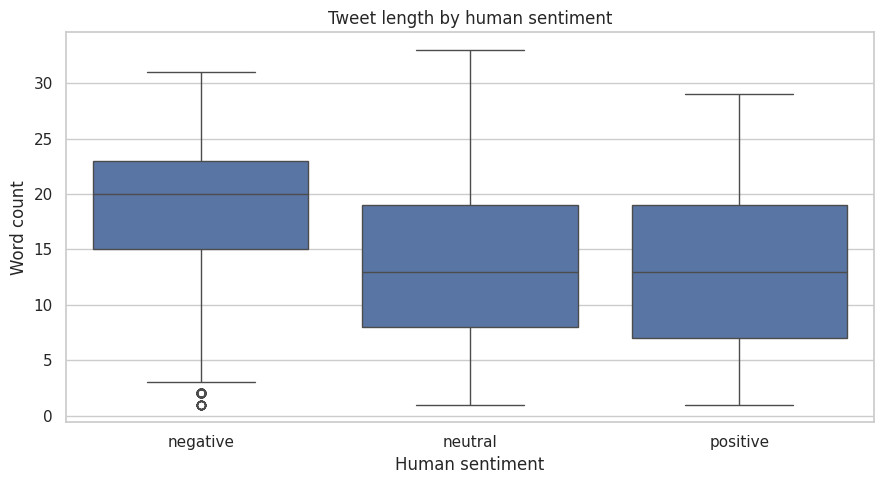

,count,mean,std,min,25%,50%,75%,max
airline_sentiment,,,,,,,,
negative,9178.0,18.44,5.97,1.0,15.0,20.0,23.0,31.0
neutral,3099.0,13.63,6.96,1.0,8.0,13.0,19.0,33.0
positive,2363.0,12.92,7.01,1.0,7.0,13.0,19.0,29.0


In [30]:
df["tweet_word_count"] = df["tokens_all"].apply(len)
plt.figure(figsize=(9, 5))
sns.boxplot(data=df[df["airline_sentiment"].isin(["negative", "neutral", "positive"])],
            x="airline_sentiment", y="tweet_word_count",
            order=["negative", "neutral", "positive"])
plt.title("Tweet length by human sentiment")
plt.xlabel("Human sentiment")
plt.ylabel("Word count")
plt.tight_layout()
plt.show()
display(df.groupby("airline_sentiment")["tweet_word_count"].describe().round(2))

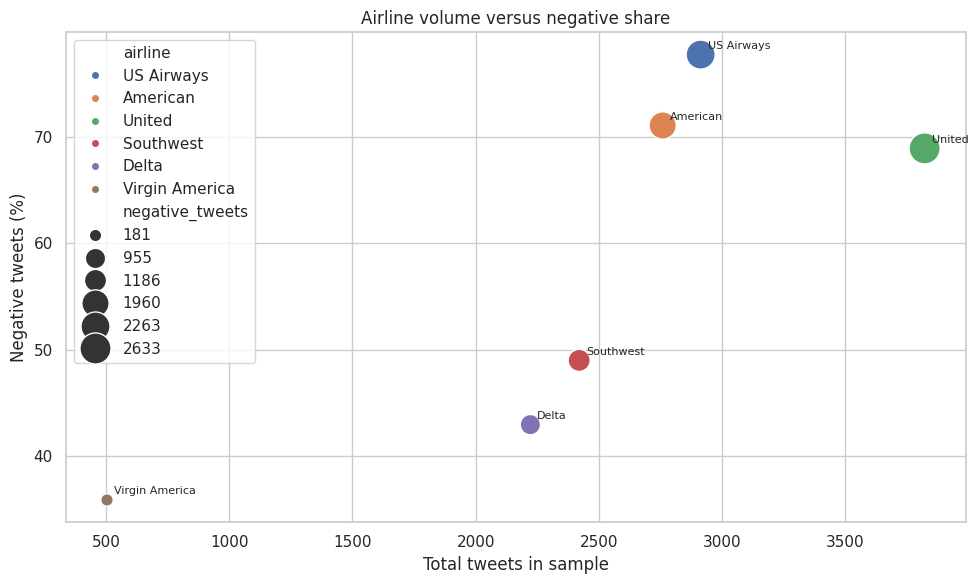

In [31]:
plot_df = airline_summary.reset_index()
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=plot_df, x="total_tweets", y="negative_share_pct",
                size="negative_tweets", hue="airline", sizes=(80, 500), ax=ax)
for _, row in plot_df.iterrows():
    ax.annotate(row["airline"], (row["total_tweets"], row["negative_share_pct"]),
                xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.set_title("Airline volume versus negative share")
ax.set_xlabel("Total tweets in sample")
ax.set_ylabel("Negative tweets (%)")
plt.tight_layout()
plt.show()

E17. How this dataset can mislead the airline
At least these limitations should accompany the charts:
1. Self-selection bias: people who post publicly may be more motivated by unusually good or bad experiences than silent passengers.
2. Platform bias: Twitter users are not a random sample of all passengers; demographics and platform usage differ.
3. Time limitation: the dataset covers a short period in February 2015, not current operations.

4. Unequal airline volume: raw counts can make airlines with more tweets look worse.
5. Annotation uncertainty: sentiment labels and complaint reasons can be uncertain or missing.
6. Context loss: a tweet may reply to another post; isolated text can be ambiguous, sarcastic or incomplete.
7. Language and location limits: slang, spelling, emojis and timezone/location metadata may be inconsistent.